# Phishing susceptibility of university students: data analysis

**Goal.** Process the raw answer log of the phishing questionnaire, remove the warm-up (practice) messages, apply pre-stated quality filters, compute robust statistics with bootstrap 95% confidence intervals, and export publication-ready figures.

**How the benchmark vocabulary maps onto this study**

| Benchmark term | In this study |
|---|---|
| Latency (ms) | Response time of a student to one message (s) |
| Load | Social-engineering cue type: urgency, authority or familiarity |
| Error rate (guardrail) | Share of wrong answers |
| Warm-up / cold start | The 2 practice messages shown first |
| Baseline vs Proposed | Students **without** vs **with** prior cybersecurity training |

> **Data note.** `data/raw/test_run.jsonl` holds real answers from the classmates survey (18 fictional messages + 2 practice messages per student). When new responses arrive, append them to the file and run **Kernel -> Restart & Run All** again.

In [1]:
import sys
import numpy as np
import pandas as pd

sys.path.insert(0, "../src")          # make src/ importable
import process_data as pdp
import visualize as viz

np.random.seed(42)                    # global seed (bootstrap also uses its own fixed seed = 42)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
print("seed fixed:", pdp.SEED, "| bootstrap resamples:", pdp.N_BOOT)

seed fixed: 42 | bootstrap resamples: 2000


## 1. Data ingestion and warm-up filtering

Each line of the `.jsonl` file is one answer of one student. The first two messages are *practice* messages (`phase == "warmup"`): students are still getting used to the interface, so these answers are slower and must not be mixed with the real measurements.

In [2]:
df = pdp.load_jsonl("../data/raw/test_run.jsonl")
print("rows:", len(df), "| students:", df["respondent"].nunique())
df.head()

rows: 800 | students: 40


,respondent,phase,item_id,order,cue_type,channel,is_phishing,answer,correct,response_time_ms,confidence_pct,consent,major,major_group,age,prior_training,training_hours,academic_year,digital_literacy,self_confidence,attention_check,completion_seconds,source,response_time_s,error,group,confidence
0,rta7dr89c,warmup,P1,0,urgency,email,True,phishing,True,4626,100,yes,кибербезопасность,IT,20,1,200,3,5,7,5,200,real,4.626,0,Trained (proposed),1.0
1,rta7dr89c,warmup,P2,0,authority,email,False,legit,True,8647,100,yes,кибербезопасность,IT,20,1,200,3,5,7,5,200,real,8.647,0,Trained (proposed),1.0
2,rta7dr89c,eval,V10,1,urgency,email,True,phishing,True,2227,100,yes,кибербезопасность,IT,20,1,200,3,5,7,5,200,real,2.227,0,Trained (proposed),1.0
3,rta7dr89c,eval,V01,2,urgency,email,True,phishing,True,4431,100,yes,кибербезопасность,IT,20,1,200,3,5,7,5,200,real,4.431,0,Trained (proposed),1.0
4,rta7dr89c,eval,V17,3,authority,messenger,True,phishing,True,8186,100,yes,кибербезопасность,IT,20,1,200,3,5,7,5,200,real,8.186,0,Trained (proposed),1.0


In [3]:
warm, ev = pdp.split_warmup(df)
ev, qc = pdp.apply_quality_filters(ev)
print("quality filters (attention check != 5, response < 1 s):", qc)
cold = pd.DataFrame({
    "median response time, s": [warm["response_time_s"].median(), ev["response_time_s"].median()],
    "answers": [len(warm), len(ev)],
}, index=["warm-up (discarded)", "evaluation (kept)"])
cold

quality filters (attention check != 5, response < 1 s): {'rows_in': 720, 'respondents_in': 40, 'respondents_failed_attention': 1, 'rows_too_fast': 4, 'rows_out': 698, 'respondents_out': 39}


,"median response time, s",answers
warm-up (discarded),9.0615,80
evaluation (kept),14.0765,698


The warm-up answers are clearly slower than the evaluation answers (the "cold-start spike"), so discarding them avoids biasing the response-time statistics. From now on only `ev` is used.

Sanity checks on the evaluation data:

In [4]:
print("missing values:", int(ev[["response_time_s", "correct", "cue_type", "channel", "group"]].isna().sum().sum()))
print("duplicate (student, message) pairs:", int(ev.duplicated(["respondent", "item_id"]).sum()))
print("answers per student (min/max):", ev.groupby("respondent").size().min(), "/", ev.groupby("respondent").size().max())
ev.groupby("group")["respondent"].nunique().rename("students per group")

missing values: 0
duplicate (student, message) pairs: 0
answers per student (min/max): 17 / 18


group
Trained (proposed)      14
Untrained (baseline)    25
Name: students per group, dtype: int64

## 2. Statistical aggregation

For every group and cue type we report the **median**, the **p25 / p75 / p95 / p99** percentiles, and a **95% bootstrap confidence interval** of the median. Because one student answers many messages, the bootstrap resamples *students* (cluster bootstrap), not single answers. The **error rate** is tracked as a guardrail metric: a faster response is only good if the students are not making more mistakes.

In [5]:
summary = pd.concat([pdp.summarize(ev, ["group", "cue_type"]).assign(channel="all"),
                     pdp.summarize(ev, ["group", "channel"]).assign(cue_type="all")], ignore_index=True)
summary.to_csv("../data/processed/metrics_summary.csv", index=False)
summary.round(2)

,group,cue_type,n_respondents,n_answers,median_s,p25_s,p75_s,p95_s,p99_s,median_ci_lo,median_ci_hi,mean_s,sd_s,error_rate,error_ci_lo,error_ci_hi,accuracy,mean_confidence,overconfidence_gap,channel
0,Trained (proposed),authority,14,83,14.96,5.39,17.06,22.56,41.99,5.90,16.24,12.51,8.98,0.05,0.01,0.09,0.95,0.96,0.00,all
1,Trained (proposed),familiarity,14,83,13.97,5.15,16.49,26.31,62.44,6.44,16.24,12.93,11.00,0.16,0.11,0.21,0.84,0.93,0.09,all
2,Trained (proposed),urgency,14,84,11.50,4.45,17.21,20.61,42.30,5.48,16.61,11.95,9.04,0.07,0.04,0.12,0.93,0.95,0.02,all
3,Untrained (baseline),authority,25,150,12.36,3.42,16.85,19.98,25.24,5.73,16.01,10.89,7.12,0.07,0.03,0.13,0.93,0.91,-0.01,all
4,Untrained (baseline),familiarity,25,150,15.06,4.97,16.95,28.43,68.99,9.25,16.29,13.59,12.78,0.22,0.17,0.27,0.78,0.90,0.12,all
5,Untrained (baseline),urgency,25,148,13.43,4.62,16.32,19.46,33.81,5.93,15.74,11.17,7.26,0.11,0.06,0.18,0.89,0.89,0.01,all
6,Trained (proposed),all,14,140,11.79,5.38,17.10,21.89,45.98,6.44,16.26,12.36,8.72,0.14,0.10,0.19,0.86,0.94,0.08,email
7,Trained (proposed),all,14,56,14.40,4.17,16.87,31.32,63.64,5.03,16.24,13.36,12.80,0.05,0.00,0.11,0.95,0.94,-0.00,messenger
8,Trained (proposed),all,14,54,14.47,4.67,16.66,20.40,37.98,5.64,16.22,11.80,8.36,0.00,0.00,0.00,1.00,0.97,-0.03,sms
9,Untrained (baseline),all,25,249,14.86,5.07,16.94,21.94,49.62,7.16,15.93,12.73,10.80,0.17,0.13,0.22,0.83,0.89,0.06,email


In [6]:
table = pdp.baseline_vs_proposed(ev)
open("../reports/baseline_vs_proposed.md", "w", encoding="utf-8").write(pdp.to_markdown(table) + "\n")
table

,Group,Students,Answers,"Response time, median (p25-p75), s","Response time, mean +- SD, s","p95 / p99, s","Median 95% CI, s","Error rate (guardrail), %","Error 95% CI, %"
0,Untrained (baseline),25,448,14.1 (4.3-16.8),11.9 +- 9.5,20.7 / 36.3,[6.1; 15.9],13.6,[10.3; 17.0]
1,Trained (proposed),14,250,14.0 (5.0-16.9),12.5 +- 9.7,23.7 / 51.7,[5.9; 16.2],9.2,[7.2; 11.2]


## 3. Guardrail metric and confidence-accuracy gap (RQ3)

`overconfidence_gap` = mean confidence (0.5-1.0) minus accuracy. A positive value means students are more confident than they are accurate.

In [7]:
gap = pdp.summarize(ev, ["group"])[["group", "accuracy", "mean_confidence", "overconfidence_gap", "error_rate", "error_ci_lo", "error_ci_hi"]]
gap.round(3)

,group,accuracy,mean_confidence,overconfidence_gap,error_rate,error_ci_lo,error_ci_hi
0,Trained (proposed),0.908,0.946,0.038,0.092,0.072,0.112
1,Untrained (baseline),0.864,0.902,0.038,0.136,0.103,0.170


## 4. Visualisation and export

Both figures follow the three rules of scientific visualisation: labelled axes with units, visible uncertainty (95% CI), and a colour-blind-safe palette with different markers / line styles / hatches. Every figure is saved as vector `.pdf` and as `.png` with 300 dpi in `reports/figures/`.

saved: ['fig1_latency_vs_load.pdf', 'fig1_latency_vs_load.png']


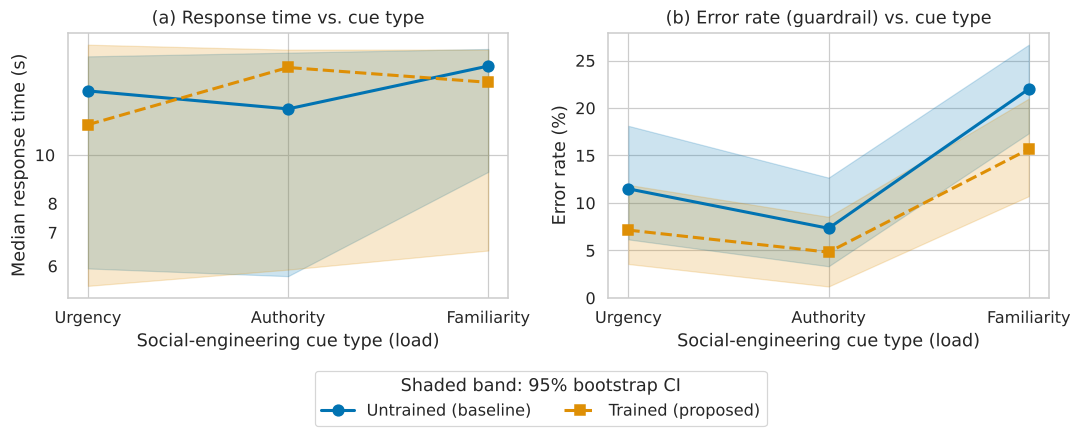

In [8]:
fig1, paths1 = viz.fig_latency_vs_load(summary, outdir="../reports/figures")
import matplotlib.pyplot as plt
plt.show()
print("saved:", [p.name for p in paths1])

saved: ['fig2_distribution_boxplot.pdf', 'fig2_distribution_boxplot.png']


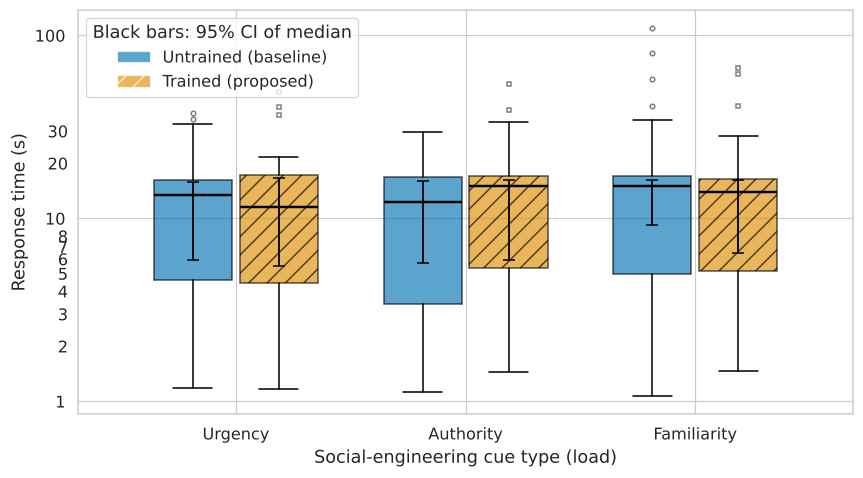

In [9]:
fig2, paths2 = viz.fig_distribution_boxplot(ev, summary, outdir="../reports/figures")
plt.show()
print("saved:", [p.name for p in paths2])

## 5. Limitations

* With few students the confidence intervals are wide; the study design targets 40-100 students.
* Participants are classmates recruited by convenience, so results describe this sample and do not generalise to all students.
* Training status and major are self-reported and cannot be verified.
* The bootstrap is a percentile bootstrap with 2000 resamples and seed 42, so every number in this notebook is reproducible.